# SignaVision Part 1: Data

## Setup

In [ ]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    REPO = "school-project-DL-SignaVision-20262027"
    if not Path(REPO).exists():
        !git clone -q https://github.com/guinat/{REPO}.git
    sys.path.insert(0, f"{REPO}/src")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from signavision.classes import CLASS_FAMILY, CLASS_NAMES, NUM_CLASSES
from signavision.config import SEED
from signavision.data import get_data_dir, load_metadata
from signavision.viz import BLUE, GRAY, save_fig, set_style

set_style()
DATA_DIR = get_data_dir()

## 1. Loading

In [3]:
train_df, test_df = load_metadata(DATA_DIR)

print(f"Train: {len(train_df)} images")
print(f"Test:  {len(test_df)} images")
print(f"Total: {len(train_df) + len(test_df)} images")
print("Classes:", train_df["ClassId"].nunique())
train_df.head()

Train: 39209 images
Test:  12630 images
Total: 51839 images
Classes: 43


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,track
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png,00020_00000
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png,00020_00000
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png,00020_00000
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png,00020_00000
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png,00020_00000


## 2. Classes

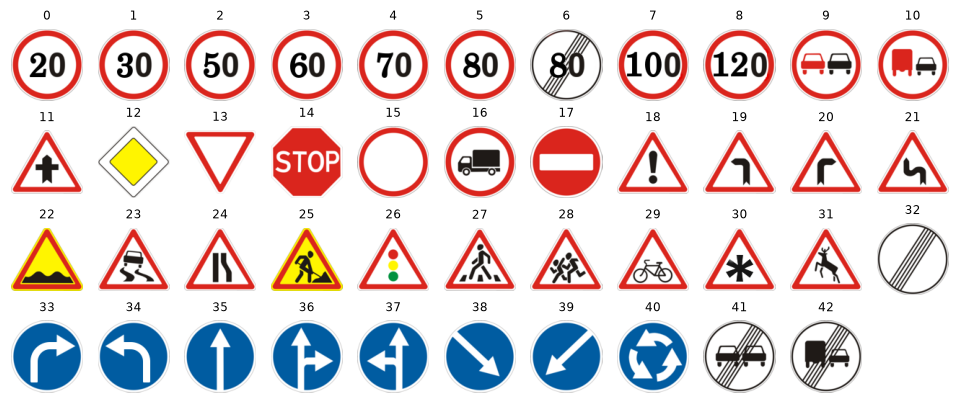

In [4]:
fig, axes = plt.subplots(4, 11, figsize=(11, 4.4))
for ax in axes.flat:
    ax.axis("off")
for c, ax in zip(range(NUM_CLASSES), axes.flat):
    ax.imshow(Image.open(DATA_DIR / "Meta" / f"{c}.png"))
    ax.set_title(c, fontsize=8)
plt.show()

## 3. Number of images per class

In [5]:
counts = pd.DataFrame({
    "name": CLASS_NAMES,
    "family": [CLASS_FAMILY[c] for c in range(NUM_CLASSES)],
    "train": train_df["ClassId"].value_counts().sort_index(),
    "test": test_df["ClassId"].value_counts().sort_index(),
})
counts["train_pct"] = (100 * counts["train"] / counts["train"].sum()).round(2)
counts

,name,family,train,test,train_pct
ClassId,,,,,
0,Speed limit 20 km/h,Speed limit,210,60,0.54
1,Speed limit 30 km/h,Speed limit,2220,720,5.66
2,Speed limit 50 km/h,Speed limit,2250,750,5.74
3,Speed limit 60 km/h,Speed limit,1410,450,3.60
4,Speed limit 70 km/h,Speed limit,1980,660,5.05
5,Speed limit 80 km/h,Speed limit,1860,630,4.74
6,End of speed limit 80 km/h,End of restriction,420,150,1.07
7,Speed limit 100 km/h,Speed limit,1440,450,3.67
8,Speed limit 120 km/h,Speed limit,1410,450,3.60


In [6]:
by_family = counts.groupby("family")[["train", "test"]].sum()
by_family["train_pct"] = (100 * by_family["train"] / by_family["train"].sum()).round(1)
print(by_family.sort_values("train", ascending=False))

c_min, c_max = counts["train"].idxmin(), counts["train"].idxmax()
print(f"\nLeast represented class: {c_min} ({CLASS_NAMES[c_min]}) -> {counts['train'].min()} images")
print(f"Most represented class:  {c_max} ({CLASS_NAMES[c_max]}) -> {counts['train'].max()} images")
print(f"Max / min ratio: {counts['train'].max() / counts['train'].min():.1f}")

                    train  test  train_pct
family                                    
Speed limit         12780  4170       32.6
Danger               7650  2370       19.5
Priority             6360  2100       16.2
Prohibition          5640  1860       14.4
Mandatory            5639  1770       14.4
End of restriction   1140   360        2.9

Least represented class: 0 (Speed limit 20 km/h) -> 210 images
Most represented class:  2 (Speed limit 50 km/h) -> 2250 images
Max / min ratio: 10.7


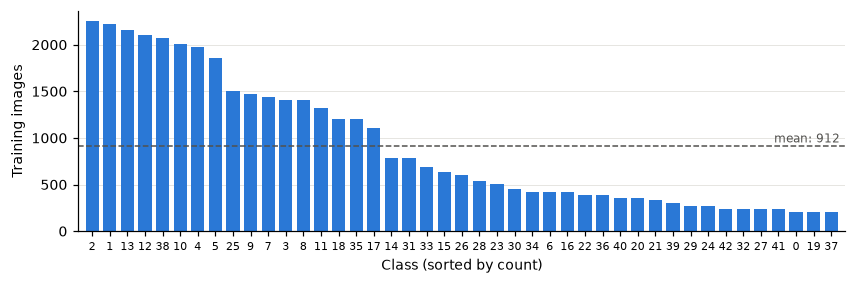

In [7]:
order = counts["train"].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 2.6))
ax.bar(range(NUM_CLASSES), order.values, color=BLUE, width=0.75)
ax.axhline(order.mean(), color=GRAY, linestyle="--", linewidth=1)
ax.text(NUM_CLASSES - 0.5, order.mean() + 40, f"mean: {order.mean():.0f}", ha="right", fontsize=8, color=GRAY)
ax.set_xticks(range(NUM_CLASSES), order.index, fontsize=7)
ax.set_xlim(-0.8, NUM_CLASSES - 0.2)
ax.set_xlabel("Class (sorted by count)")
ax.set_ylabel("Training images")
ax.grid(axis="x", visible=False)
save_fig(fig, "class_distribution.pdf")
plt.show()

## 4. Image size and format

In [8]:
for name, df in [("train", train_df), ("test", test_df)]:
    print(f"{name} - width: {df['Width'].min()} to {df['Width'].max()} (median {df['Width'].median():.0f})"
          f" - height: {df['Height'].min()} to {df['Height'].max()} (median {df['Height'].median():.0f})")

ratio = train_df["Width"] / train_df["Height"]
print(f"Width / height ratio: median {ratio.median():.2f}, 95% of images between {ratio.quantile(0.025):.2f} and {ratio.quantile(0.975):.2f}")
print(f"Images with a side smaller than 32 px: {(train_df[['Width', 'Height']].min(axis=1) < 32).mean():.1%}")

# Actual file format (PIL only reads the header, so this is fast)
paths = pd.concat([train_df["Path"], test_df["Path"]])
modes = pd.Series([Image.open(DATA_DIR / p).mode for p in paths]).value_counts()
print("Extensions:", paths.str.rsplit(".", n=1).str[-1].value_counts().to_dict(), "| modes:", modes.to_dict())

print("Tracks in train:", train_df["track"].nunique(),
      "| images per track:", train_df["track"].value_counts().value_counts().to_dict())

train - width: 25 to 243 (median 43) - height: 25 to 225 (median 43)
test - width: 25 to 266 (median 43) - height: 25 to 232 (median 43)
Width / height ratio: median 1.00, 95% of images between 0.87 and 1.15
Images with a side smaller than 32 px: 16.6%


Extensions: {'png': 51839} | modes: {'RGB': 51839}
Tracks in train: 1307 | images per track: {30: 1306, 29: 1}


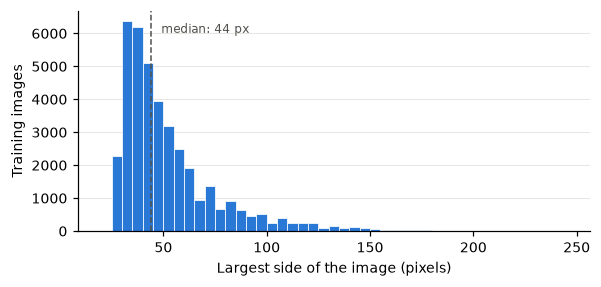

In [9]:
side = train_df[["Width", "Height"]].max(axis=1)

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(side, bins=np.arange(20, 250, 5), color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(side.median(), color=GRAY, linestyle="--", linewidth=1)
ax.text(side.median() + 5, ax.get_ylim()[1] * 0.9, f"median: {side.median():.0f} px", fontsize=8, color=GRAY)
ax.set_xlabel("Largest side of the image (pixels)")
ax.set_ylabel("Training images")
ax.grid(axis="x", visible=False)
save_fig(fig, "image_sizes.pdf")
plt.show()

## 5. Sample images

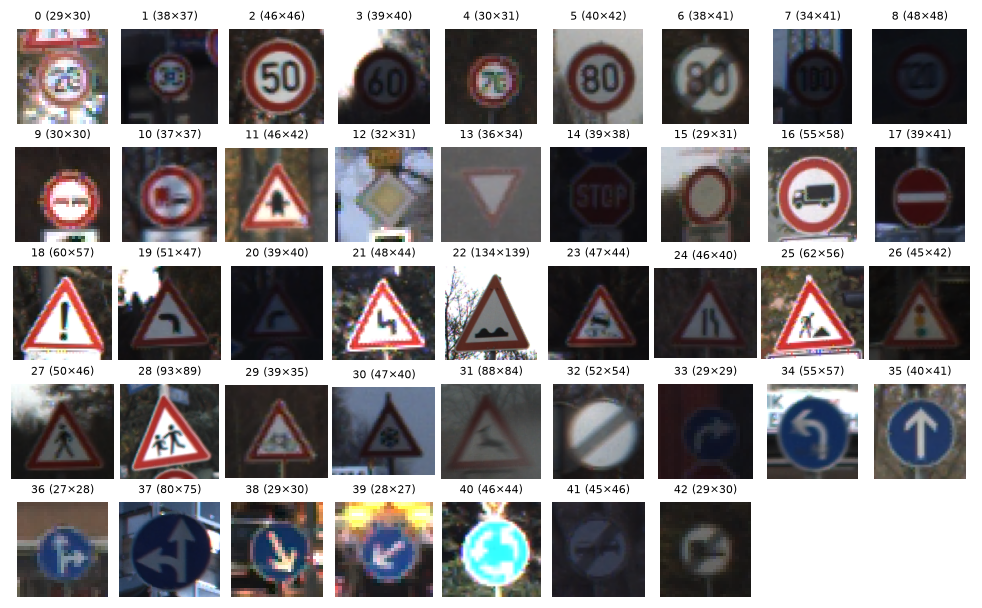

In [10]:
# One random image per class
samples = train_df.groupby("ClassId").sample(1, random_state=SEED).sort_values("ClassId")

fig, axes = plt.subplots(5, 9, figsize=(9, 5.6))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    ax.imshow(Image.open(DATA_DIR / row["Path"]))
    ax.set_title(f"{row['ClassId']} ({row['Width']}×{row['Height']})", fontsize=7)
fig.tight_layout(h_pad=0.6, w_pad=0.3)
save_fig(fig, "class_examples.png")
plt.show()

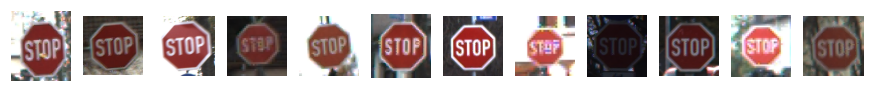

In [11]:
# Intra-class variability: 12 Stop signs taken from different tracks
stops = (train_df[train_df["ClassId"] == 14]
         .groupby("track").sample(1, random_state=SEED)
         .sample(12, random_state=SEED))

fig, axes = plt.subplots(1, 12, figsize=(10, 1.2))
for ax, (_, row) in zip(axes, stops.iterrows()):
    ax.imshow(Image.open(DATA_DIR / row["Path"]))
    ax.axis("off")
save_fig(fig, "stop_variability.png")
plt.show()